20163_3742f394_1 (parts_fine): исходная тесселяция 16254 треуг., габарит 28.8 мм, замкнут True
подложка 152930 треуг.
рабочий меш 30000 треуг. — это видит сеть


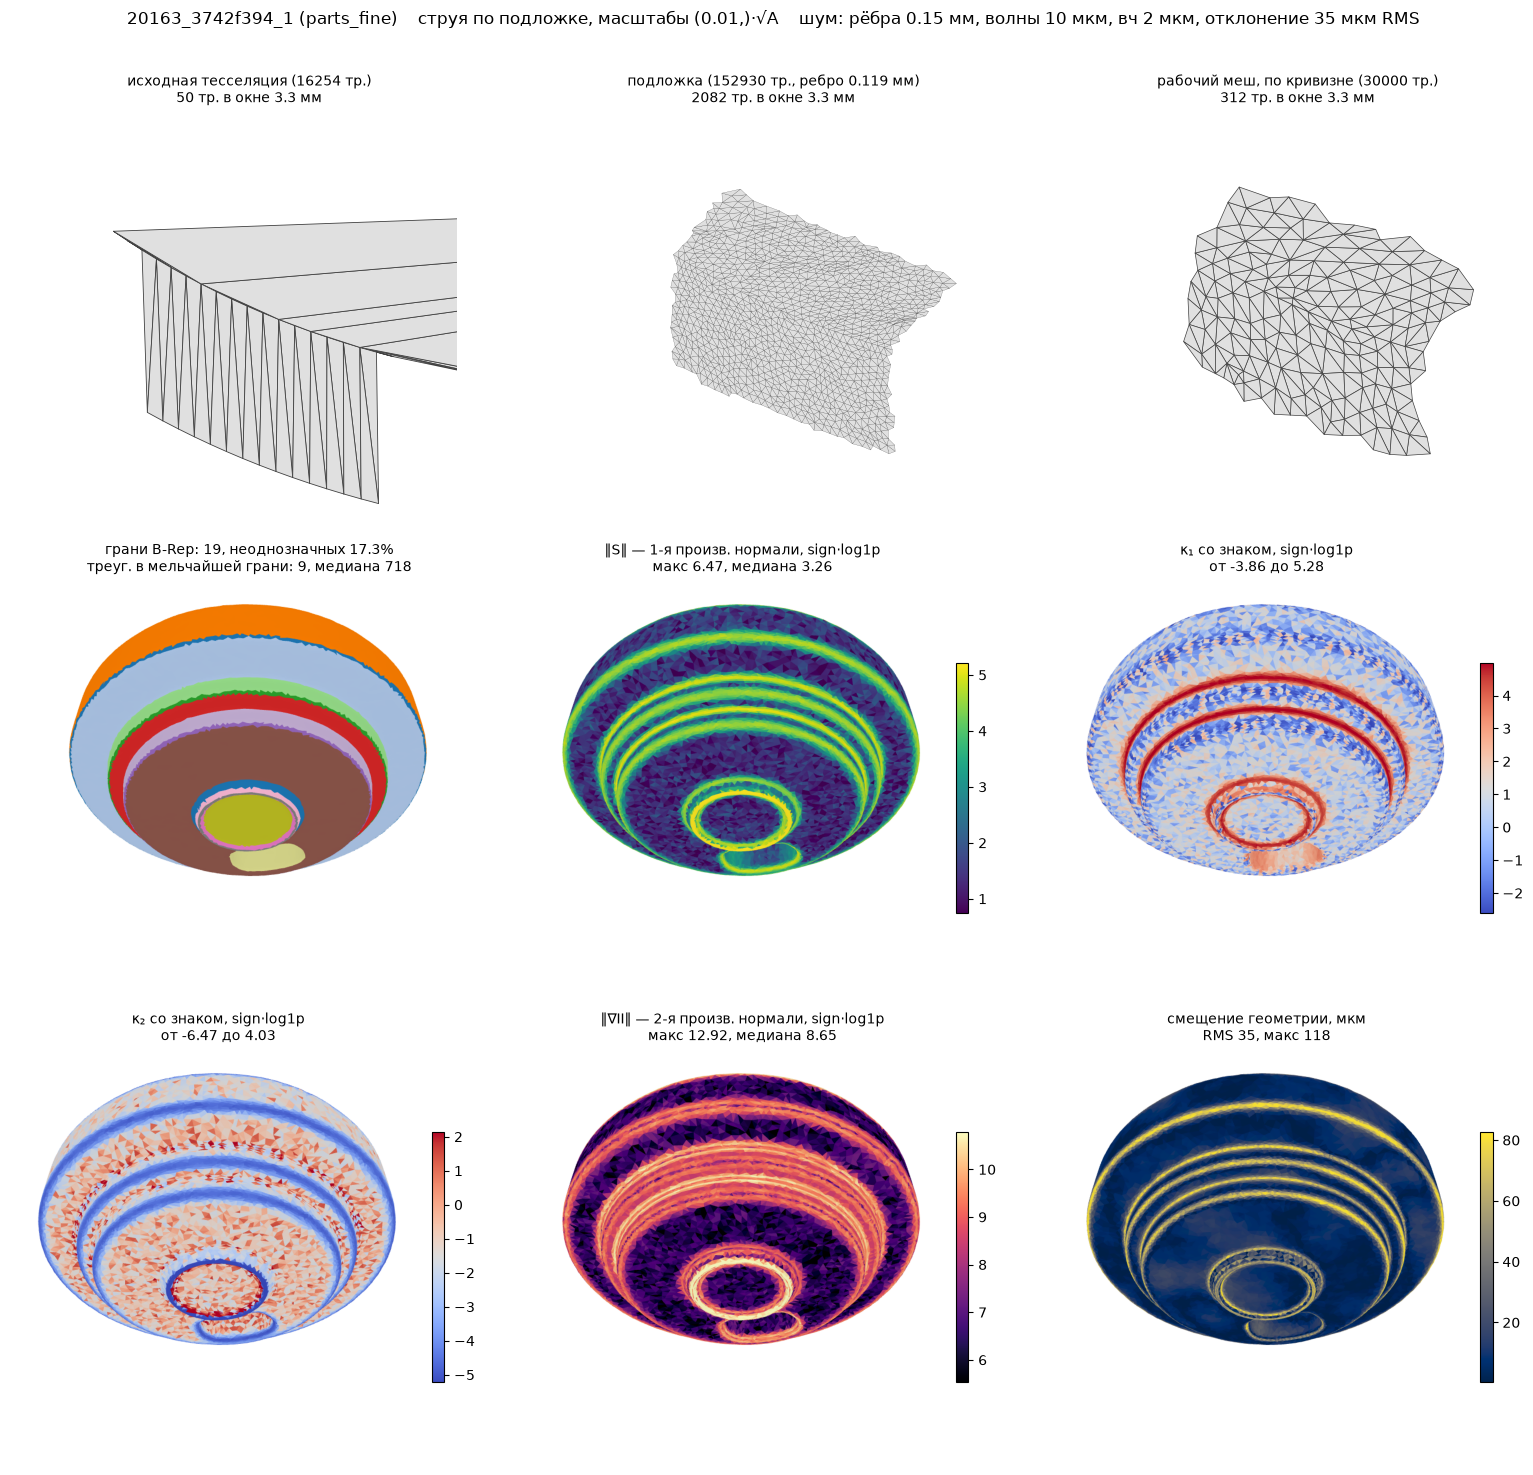

In [1]:
import os
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import trimesh
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

sys.path.insert(0, "/home/daniil/curv_ai_segm")
from dataset import features as FE
from dataset import noise as N
from dataset import remesh as R
from src import visualization as viz
from src.config import CFG
from src.data import compress_curvature

SOURCE = "20163_3742f394_1"  # uid детали датасета ЛИБО путь к любому .stl / .ply
PARTS = "parts_fine"          # parts_fine — наша тесселяция STEP, parts — старая
                              # грубая step-dataset, для сравнения той же детали
NOISE = True                 # синтетический шум; для реального скана выключить
EDGES = CFG.noise.edge_radius_mm   # целевой радиус скругления рёбер, мм — как в кэше
WAVE  = CFG.noise.wave_sigma_mm    # амплитуда длинноволновой деформации, мм — как в кэше
WIN   = 12                    # ширина фрагмента каркаса, в рёбрах рабочего меша
AZIM  = 240                    # ракурс: поворот вокруг вертикали, градусы
ELEV  = -40                    # ракурс: подъём над горизонтом, градусы
ADAPT = True                  # рабочий меш: упрощение подложки (плотность по кривизне)
                              # False — равномерный ремеш

d = os.path.expanduser(f"~/curv_ai_segm/dataset/data/{PARTS}/{SOURCE}")
if os.path.isdir(d):                       # деталь датасета: разметка есть
    src = trimesh.load(f"{d}/mesh.ply", process=False)
    fid = np.load(f"{d}/face_id.npy")
    title = f"{SOURCE} ({PARTS})"
else:                                      # произвольный файл: разметки нет
    src = trimesh.load(os.path.expanduser(SOURCE), process=False)
    src.remove_unreferenced_vertices()
    fid = None
    title = os.path.basename(SOURCE)
print(f"{title}: исходная тесселяция {len(src.faces)} треуг., габарит "
      f"{np.linalg.norm(src.extents):.1f} мм, замкнут {src.is_watertight}")

# 1. подложка: носитель шума и источник окрестностей для струи
sub = R.substrate(src)
Vs, Fs = np.asarray(sub.vertices), np.asarray(sub.faces)
Ns = np.asarray(sub.vertex_normals)
print(f"подложка {len(Fs)} треуг.")
s_sub = float(np.median(np.linalg.norm(Vs[sub.edges[:, 0]] - Vs[sub.edges[:, 1]], axis=1)))

# 2. шум на подложке: рёбра -> длинные волны -> высокочастотный коррелированный
rng = np.random.default_rng(0)
esrc, edst = N.mesh_edges(Fs)
if NOISE:
    Vn = N.round_edges(Vs, esrc, edst, radius=EDGES, spacing=s_sub)
    Vn = N.waviness(Vn, Ns, s_sub, rng, sigma=WAVE)
    Vn = N.high_frequency(Vn, Ns, s_sub, rng)
else:
    Vn = Vs
sub_n = trimesh.Trimesh(Vn, Fs, process=False)

# 3. рабочий меш 30 тыс. треугольников; разметка — на зашумлённом, как в кэше
mesh_of = R.decimate if ADAPT else R.remesh
work, work_n = mesh_of(sub), mesh_of(sub_n)
lab = R.transfer_labels(src, fid, work_n) if fid is not None else None
amb = R.ambiguous(work_n, lab) if lab is not None else None
print(f"рабочий меш {len(work_n.faces)} треуг. — это видит сеть")
step = float(np.median(np.linalg.norm(
    work.vertices[work.edges[:, 0]] - work.vertices[work.edges[:, 1]], axis=1)))

# 4. признаки: струя по подложке, значения на центроидах рабочего меша
X, names = FE.compute(sub, work)
Xn, _ = FE.compute(sub_n, work_n)
H0 = FE.SCALES_REL[0]
col = lambda M, nm: M[:, names.index(f"{nm}@{H0}")]
k1, k2, dII = col(X, "k1"), col(X, "k2"), col(X, "dII")
S = np.hypot(k1, k2)                                   # ‖S‖ = sqrt(k1^2 + k2^2)
Sn = np.hypot(col(Xn, "k1"), col(Xn, "k2"))
dIIn = col(Xn, "dII")
# Шкала как на входе сети: знаковый log1p на каналах кривизны, если он включён.
LOG = CFG.model.log_curvature
Xv = compress_curvature(Xn.T, names).T if LOG else Xn
scale_txt = "sign·log1p" if LOG else "линейно"

dev = trimesh.proximity.closest_point(work, work_n.triangles.mean(axis=1))[1] * 1000

fig = plt.figure(figsize=(16, 15))
ctr = work.triangles.mean(axis=1)[np.argsort(S)[int(0.995 * len(S))]]
half = WIN * step / 2
for j, (m, name, lw) in enumerate([
        (src, f"исходная тесселяция ({len(src.faces)} тр.)", 0.6),
        (sub, f"подложка ({len(Fs)} тр., ребро {s_sub:.3f} мм)", 0.15),
        (work, ("рабочий меш, " + ("по кривизне" if ADAPT else "равномерный")
                + f" ({len(work.faces)} тр.)"), 0.5)]):
    ax = fig.add_subplot(3, 3, j + 1, projection="3d")
    v, f = np.asarray(m.vertices), np.asarray(m.faces)
    keep = f[np.any(np.all(np.abs(v - ctr) < half, axis=1)[f], axis=1)]
    ax.add_collection3d(Poly3DCollection(v[keep], facecolor="0.88",
                                         edgecolor="0.25", lw=lw))
    for setter, a in zip((ax.set_xlim, ax.set_ylim, ax.set_zlim), range(3)):
        setter(ctr[a] - half, ctr[a] + half)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=ELEV, azim=AZIM)
    ax.set_title(f"{name}\n{len(keep)} тр. в окне {WIN * step:.1f} мм", fontsize=10)
    ax.axis("off")


def panel(pos, mesh, values, title, cmap="viridis", bar=True, clip=(2, 98),
          vrange=None):
    """vrange=(lo, hi) — АБСОЛЮТНЫЕ границы шкалы. Без них каждая панель
    считает свои перцентили, и чистое с зашумлённым получают разные шкалы —
    разница между ними тогда не видна вообще."""
    ax = fig.add_subplot(3, 3, pos)
    lo, hi = vrange if vrange is not None else np.percentile(values, list(clip))
    v = np.clip(values, lo, hi)
    ax.imshow(viz.render(mesh, viz.face_colors(v, np.asarray(mesh.faces),
                                               cmap=cmap, per_face=True,
                                               lo=0, hi=100),
                         azim=AZIM, elev=ELEV))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    if bar:
        fig.colorbar(mpl.cm.ScalarMappable(mpl.colors.Normalize(lo, hi),
                                           mpl.colormaps[cmap]),
                     ax=ax, shrink=0.6, pad=0.01)


if lab is not None:
    cnt = np.bincount(lab.astype(int))
    cnt = cnt[cnt > 0]
    panel(4, work_n, lab.astype(float),
          f"грани B-Rep: {len(np.unique(lab))}, неоднозначных {amb.mean() * 100:.1f}%\n"
          f"треуг. в мельчайшей грани: {cnt.min()}, медиана {int(np.median(cnt))}",
          cmap="tab20", bar=False)
else:
    panel(4, work, np.zeros(len(work.faces)),
          f"разметки нет — внешний файл\n{len(work.faces)} треуг. в рабочем меше",
          cmap="Greys", bar=False)
# Показываем ЗАШУМЛЁННЫЕ данные в двух шкалах: целевой домен шумный,
# и решать про логарифм надо по нему, а не по чистому CAD.
# Всё на ЗАШУМЛЁННЫХ данных: целевой домен шумный, смотреть надо по нему.
# Шкала как на входе сети (см. LOG выше), обрезка по перцентилям 2/98.
k1n, k2n = col(Xv, "k1"), col(Xv, "k2")
Sv, dIIv = col(Xv, "S"), col(Xv, "dII")
panel(5, work_n, Sv, f"‖S‖ — 1-я произв. нормали, {scale_txt}\n"
      f"макс {Sv.max():.2f}, медиана {np.median(Sv):.2f}")
panel(6, work_n, k1n, f"κ₁ со знаком, {scale_txt}\nот {k1n.min():.2f} до {k1n.max():.2f}",
      cmap="coolwarm")
panel(7, work_n, k2n, f"κ₂ со знаком, {scale_txt}\nот {k2n.min():.2f} до {k2n.max():.2f}",
      cmap="coolwarm")
panel(8, work_n, dIIv, f"‖∇II‖ — 2-я произв. нормали, {scale_txt}\n"
      f"макс {dIIv.max():.2f}, медиана {np.median(dIIv):.2f}", cmap="magma")
panel(9, work_n, dev, f"смещение геометрии, мкм\n"
      f"RMS {np.sqrt((dev ** 2).mean()):.0f}, макс {dev.max():.0f}", cmap="cividis")

noise_txt = (f"шум: рёбра {EDGES} мм, волны {WAVE * 1000:.0f} мкм, вч 2 мкм, "
             f"отклонение {np.sqrt((dev ** 2).mean()):.0f} мкм RMS"
             if NOISE else "без синтетического шума")
fig.suptitle(f"{title}    струя по подложке, масштабы {FE.SCALES_REL}·√A    "
             f"{noise_txt}", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()